In [1]:
# One-time dependency install (leave commented once packages are installed).
# Uncomment and run only if this notebook environment is missing a package:
# %pip install pandas matplotlib ipykernel jinja2

# In VS Code, select the project interpreter: .venv\Scripts\python.exe
import sys
print(f"Notebook Python: {sys.executable}")

Notebook Python: C:\Users\Montana\Documents\GitHub\DSA8670_Montana_Week7_Codex\.venv\Scripts\python.exe


# **Selected analytical question:** Among houses with the same above-ground living area, how do expected sale prices differ across Ames neighborhoods?

The analysis uses a linear regression with a separate neighborhood intercept and a shared living-area slope. It compares each neighborhood at the dataset-wide mean living area. This is a descriptive adjustment, not a causal estimate.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# This notebook lives in analysis/notebooks, so the CSV is two levels above it.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks" and PROJECT_ROOT.parent.name == "analysis":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
DATA_PATH = PROJECT_ROOT / "AmesHousing-1.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Open the project root in VS Code, "
        "or update DATA_PATH to the CSV location."
    )

ames = pd.read_csv(DATA_PATH, na_values=["NA"])
print(f"Loaded {ames.shape[0]:,} rows and {ames.shape[1]:,} columns from {DATA_PATH.name}")
display(ames.head())


Loaded 2,930 rows and 82 columns from AmesHousing-1.csv


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


## 1. Check the shape and quality of the data

Review column types, duplicate rows, missingness, and basic ranges for the fields tied to the question. The full missing-value table is shown so we can distinguish structural blanks (for example, no garage) from issues that affect the analysis.


In [3]:
print("Shape:", ames.shape)
print("Duplicate rows:", ames.duplicated().sum())
display(ames.dtypes.rename("dtype").to_frame())
missing = (
    ames.isna().sum().rename("missing_count").to_frame()
    .assign(missing_percent=lambda x: (100 * x["missing_count"] / len(ames)).round(1))
    .query("missing_count > 0")
    .sort_values("missing_count", ascending=False)
)
display(missing)
display(ames[["SalePrice", "Gr Liv Area", "Neighborhood", "Yr Sold"]].describe(include="all").T)


Shape: (2930, 82)
Duplicate rows: 0


,dtype
Order,int64
PID,int64
MS SubClass,int64
MS Zoning,str
Lot Frontage,float64
...,...
Mo Sold,int64
Yr Sold,int64
Sale Type,str
Sale Condition,str


,missing_count,missing_percent
Pool QC,2917,99.6
Misc Feature,2824,96.4
Alley,2732,93.2
Fence,2358,80.5
Mas Vnr Type,1775,60.6
Fireplace Qu,1422,48.5
Lot Frontage,490,16.7
Garage Qual,159,5.4
Garage Cond,159,5.4
Garage Yr Blt,159,5.4


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
SalePrice,2930.0,NaN,NaN,NaN,180796.060068,79886.692357,12789.0,129500.0,160000.0,213500.0,755000.0
Gr Liv Area,2930.0,NaN,NaN,NaN,1499.690444,505.508887,334.0,1126.0,1442.0,1742.75,5642.0
Neighborhood,2930,28,NAmes,443,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Yr Sold,2930.0,NaN,NaN,NaN,2007.790444,1.316613,2006.0,2007.0,2008.0,2009.0,2010.0


## 2. Compare sale prices across neighborhoods

The table sorts neighborhoods by median sale price and includes the number of sales and median above-ground living area. Neighborhoods with few records can have unstable medians, so use the sample count when interpreting the rankings.


In [4]:
neighborhood_summary = (
    ames.groupby("Neighborhood", dropna=False)
    .agg(
        sales=("SalePrice", "size"),
        median_sale_price=("SalePrice", "median"),
        mean_sale_price=("SalePrice", "mean"),
        median_living_area=("Gr Liv Area", "median"),
    )
    .sort_values("median_sale_price", ascending=False)
)
display(neighborhood_summary.style.format({
    "median_sale_price": "${:,.0f}",
    "mean_sale_price": "${:,.0f}",
    "median_living_area": "{:,.0f} sq ft",
}))


,sales,median_sale_price,mean_sale_price,median_living_area
Neighborhood,,,,
StoneBr,51,"$319,000","$324,229","1,767 sq ft"
NridgHt,166,"$317,750","$322,018","1,832 sq ft"
NoRidge,71,"$302,000","$330,319","2,418 sq ft"
GrnHill,2,"$280,000","$280,000","1,398 sq ft"
Veenker,24,"$250,250","$248,315","1,706 sq ft"
Timber,72,"$232,106","$246,600","1,650 sq ft"
Somerst,182,"$225,500","$229,707","1,555 sq ft"
Crawfor,103,"$200,624","$207,551","1,648 sq ft"
CollgCr,267,"$200,000","$201,803","1,504 sq ft"


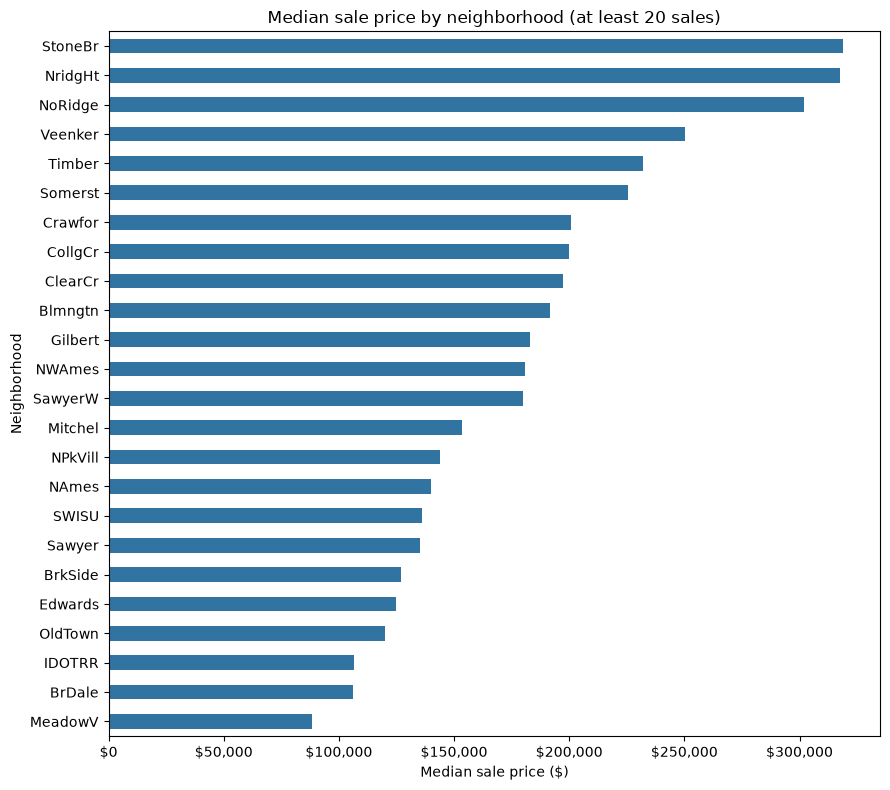

In [5]:
# For readability, show neighborhoods with at least 20 recorded sales.
plot_neighborhoods = neighborhood_summary.query("sales >= 20").sort_values("median_sale_price")
ax = plot_neighborhoods["median_sale_price"].plot.barh(figsize=(9, 8), color="#3274a1")
ax.set_title("Median sale price by neighborhood (at least 20 sales)")
ax.set_xlabel("Median sale price ($)")
ax.set_ylabel("Neighborhood")
ax.xaxis.set_major_formatter(lambda value, position: f"${value:,.0f}")
plt.tight_layout()
plt.show()


## 3. Explore living area and sale price together

A scatterplot shows the spread and possible outliers. The correlation is a compact measure of linear association, not evidence that living area alone causes a particular sale price.


Pearson correlation between sale price and living area: 0.707


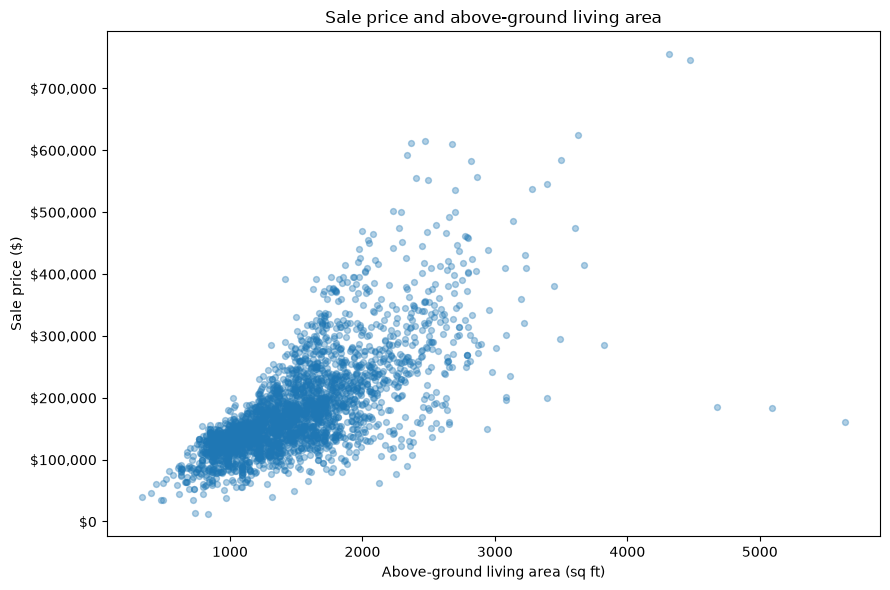

In [6]:
analysis_data = ames[["SalePrice", "Gr Liv Area", "Neighborhood"]].dropna().copy()
correlation = analysis_data["SalePrice"].corr(analysis_data["Gr Liv Area"])
print(f"Pearson correlation between sale price and living area: {correlation:.3f}")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(analysis_data["Gr Liv Area"], analysis_data["SalePrice"], alpha=0.35, s=18)
ax.set_title("Sale price and above-ground living area")
ax.set_xlabel("Above-ground living area (sq ft)")
ax.set_ylabel("Sale price ($)")
ax.yaxis.set_major_formatter(lambda value, position: f"${value:,.0f}")
plt.tight_layout()
plt.show()


## 4. Compare size patterns by neighborhood

This view uses neighborhood medians to reduce clutter. It helps us see whether high-price neighborhoods also tend to have larger homes. It remains an unadjusted descriptive comparison.


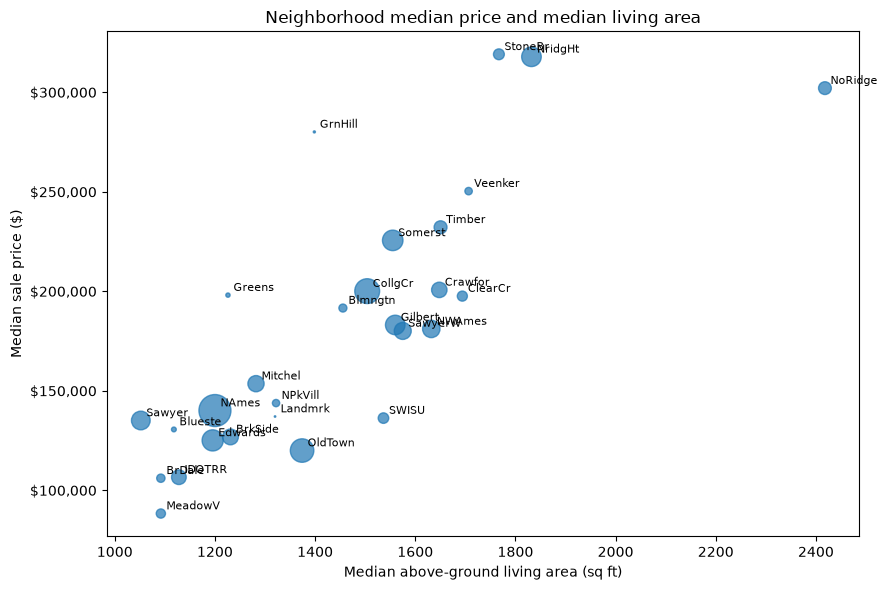

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(
    neighborhood_summary["median_living_area"],
    neighborhood_summary["median_sale_price"],
    s=neighborhood_summary["sales"] * 1.2,
    alpha=0.7,
)
for neighborhood, row in neighborhood_summary.iterrows():
    ax.annotate(neighborhood, (row["median_living_area"], row["median_sale_price"]),
                xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_title("Neighborhood median price and median living area")
ax.set_xlabel("Median above-ground living area (sq ft)")
ax.set_ylabel("Median sale price ($)")
ax.yaxis.set_major_formatter(lambda value, position: f"${value:,.0f}")
plt.tight_layout()
plt.show()


## Questions for our review

- Which neighborhood comparisons look meaningful after considering their sample sizes?
- Do the scatterplots suggest a simple linear relationship, or do outliers and uneven spread matter?
- Should the final question focus on descriptive neighborhood differences, or should we estimate neighborhood differences after adjusting for living area?
- Are there data-cleaning choices that need to be documented before the final analysis?

**Next step:** Review these outputs together, choose the final wording of the analytical question, and then decide whether a simple adjustment for living area is appropriate.


## 5. Estimate neighborhood differences adjusted for living area

We fit an ordinary least squares model with one intercept for each neighborhood and a common linear relationship between above-ground living area and sale price. Centering living area at its overall mean makes each neighborhood intercept its estimated sale price at that common size. The model does not adjust for other property features.

In [8]:
import numpy as np

model_data = ames[["SalePrice", "Gr Liv Area", "Neighborhood"]].dropna().copy()
reference_living_area = model_data["Gr Liv Area"].mean()
area_centered = model_data["Gr Liv Area"] - reference_living_area
neighborhood_dummies = pd.get_dummies(model_data["Neighborhood"], dtype=float)
design = pd.concat([neighborhood_dummies, area_centered.rename("living_area_centered")], axis=1)
y = model_data["SalePrice"].to_numpy(dtype=float)
coefficients, _, rank, _ = np.linalg.lstsq(design.to_numpy(), y, rcond=None)
if rank != design.shape[1]:
    raise ValueError("The neighborhood and living-area design matrix is rank deficient.")
fitted = design.to_numpy() @ coefficients
residuals = y - fitted
r_squared = 1 - np.sum(residuals**2) / np.sum((y - y.mean())**2)
rmse = np.sqrt(np.mean(residuals**2))
living_area_slope = coefficients[-1]

adjusted_prices = pd.Series(coefficients[:-1], index=neighborhood_dummies.columns)
neighborhood_analysis = pd.DataFrame({
    "sales": model_data.groupby("Neighborhood").size(),
    "raw_median_sale_price": model_data.groupby("Neighborhood")["SalePrice"].median(),
    "adjusted_price_at_mean_living_area": adjusted_prices,
})
neighborhood_analysis["adjusted_difference_from_overall_mean"] = (
    neighborhood_analysis["adjusted_price_at_mean_living_area"] - model_data["SalePrice"].mean()
)
neighborhood_analysis = neighborhood_analysis.sort_values(
    "adjusted_price_at_mean_living_area", ascending=False
)

print(f"Analysis sample: {len(model_data):,} houses across {len(neighborhood_dummies.columns)} neighborhoods")
print(f"Reference living area: {reference_living_area:,.0f} sq ft")
print(f"Estimated sale-price change per additional sq ft: ${living_area_slope:,.2f}")
print(f"Model R-squared: {r_squared:.3f}; RMSE: ${rmse:,.0f}")
display(neighborhood_analysis.style.format({
    "raw_median_sale_price": "${:,.0f}",
    "adjusted_price_at_mean_living_area": "${:,.0f}",
    "adjusted_difference_from_overall_mean": "${:+,.0f}",
}))

table_path = PROJECT_ROOT / "analysis" / "outputs" / "tables" / "neighborhood_adjusted_summary.csv"
neighborhood_analysis.to_csv(table_path, index_label="Neighborhood", float_format="%.2f")
print(f"Saved summary table to {table_path.relative_to(PROJECT_ROOT)}")

Analysis sample: 2,930 houses across 28 neighborhoods
Reference living area: 1,500 sq ft
Estimated sale-price change per additional sq ft: $77.30
Model R-squared: 0.745; RMSE: $40,322


,sales,raw_median_sale_price,adjusted_price_at_mean_living_area,adjusted_difference_from_overall_mean
StoneBr,51,"$319,000","$289,480","$+108,684"
GrnHill,2,"$280,000","$287,822","$+107,026"
NridgHt,166,"$317,750","$287,778","$+106,982"
NoRidge,71,"$302,000","$254,491","$+73,695"
Timber,72,"$232,106","$229,984","$+49,188"
Veenker,24,"$250,250","$223,590","$+42,794"
Somerst,182,"$225,500","$221,580","$+40,784"
Greens,8,"$198,000","$220,002","$+39,206"
Blmngtn,28,"$191,500","$203,990","$+23,194"
CollgCr,267,"$200,000","$202,079","$+21,283"


Saved summary table to analysis\outputs\tables\neighborhood_adjusted_summary.csv


## 6. Compare raw and adjusted neighborhood prices

The chart compares each neighborhood observed median sale price with its model-estimated price at the overall mean living area. To keep the chart readable, it displays neighborhoods with at least 20 sales. The table above retains all neighborhoods.

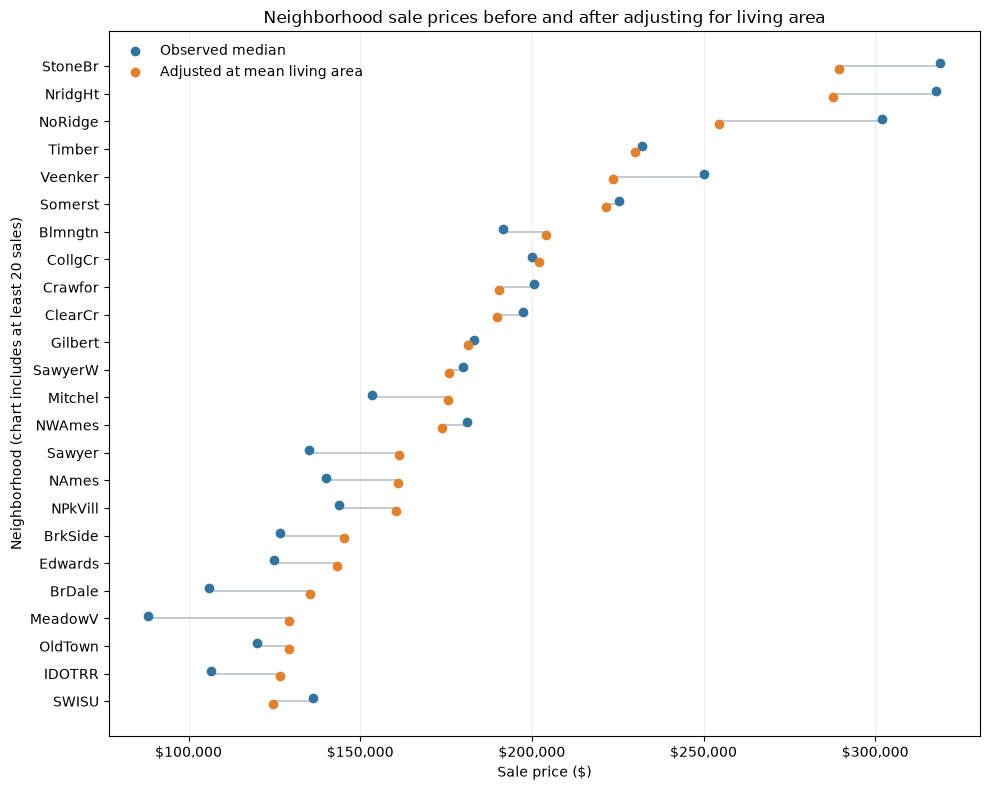

Saved chart to analysis\outputs\figures\neighborhood_adjusted_prices.png


In [9]:
# Keep the full table above; filter only the chart for legibility.
plot_data = neighborhood_analysis.query("sales >= 20").sort_values("adjusted_price_at_mean_living_area")
y_positions = np.arange(len(plot_data))
fig, ax = plt.subplots(figsize=(10, 8))
for y_pos, (_, row) in zip(y_positions, plot_data.iterrows()):
    ax.plot([row["raw_median_sale_price"], row["adjusted_price_at_mean_living_area"]], [y_pos, y_pos], color="#b8c2cc", linewidth=1.2, zorder=1)
ax.scatter(plot_data["raw_median_sale_price"], y_positions + 0.10, label="Observed median", color="#3274a1", s=36, zorder=2)
ax.scatter(plot_data["adjusted_price_at_mean_living_area"], y_positions - 0.10, label="Adjusted at mean living area", color="#e1812c", s=36, zorder=2)
ax.set_yticks(y_positions, plot_data.index)
ax.set_title("Neighborhood sale prices before and after adjusting for living area")
ax.set_xlabel("Sale price ($)")
ax.set_ylabel("Neighborhood (chart includes at least 20 sales)")
ax.xaxis.set_major_formatter(lambda value, position: f"${value:,.0f}")
ax.legend(frameon=False)
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
figure_path = PROJECT_ROOT / "analysis" / "outputs" / "figures" / "neighborhood_adjusted_prices.png"
plt.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved chart to {figure_path.relative_to(PROJECT_ROOT)}")

## 7. Findings and interpretation

At the dataset-wide mean living area (about 1,500 sq ft), adjusted expected sale prices range from about $124,500 in SWISU to $289,500 in StoneBr. Among neighborhoods with at least 20 sales, StoneBr (51 sales), NridgHt (166), and NoRidge (71) have the highest adjusted estimates. SWISU (48), IDOTRR (93), and OldTown (239) have the lowest. GrnHill’s adjusted estimate is about $287,800, but it is based on only two sales, so it is uncertain and excluded from the chart.

The fitted model estimates an average $77.30 increase in sale price per additional square foot of above-ground living area. Neighborhood and living area together explain about 74.5% of the variation in sale prices in this sample (R-squared = 0.745); the root mean squared error is about $40,322. The neighborhood differences remain substantial after the model accounts for living area.

These comparisons are descriptive, not causal. The model assumes a shared linear relationship between living area and price across neighborhoods. It does not adjust for overall quality, age, condition, sale year, or other property features, and estimates for neighborhoods with few sales are less stable.